# A simple non-Poissonian example

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
sys.path.append('/zfs/nrodd/NPTFit/Full_Testing/')

import copy
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp

import bayesian_scan_models as bsm #module for performing scan
# import analysis_classes.fermi_analysis as fa  #module for analysing scan

%matplotlib inline

## Define the directories and physics variables for the scan

In [2]:
work_dir = '/zfs/nrodd/NPTFit/Full_Testing/'
psf_dir = work_dir + '/psf_dir/'
tag = 'Example'
run_tag = 'NPTF_test_en_8_16' 
nside=128

## Now we will make an instance of bayesian_scan_models to setup the template scan

### Setting up the scan

In [3]:
iso_temp = hp.ud_grade(np.load("../../Fermi_Data/Template_iso.npy"),nside,power=-2)

In [4]:
fermi_data = hp.ud_grade(np.load("../../Fermi_Data/FermiData_counts.npy"),nside,power=-2)
fermi_exposure = hp.ud_grade(np.load("../../Fermi_Data/FermiData_exposure.npy"),nside,power=-2)
fermi_psc_mask = hp.ud_grade(np.load("../../Fermi_Data/FermiData_pscmask.npy"),nside,power=-2)

In [5]:
b = bsm.bayesian_scan_NPTF(tag=tag,nside=nside,work_dir=work_dir,psf_dir=psf_dir)
b.load_data(fermi_data, fermi_exposure)

In [6]:
import create_mask as cm
analysis_mask = cm.make_mask_total(nside, mask_ring = True, outer = 2, ring_b = 90-150)
b.load_mask(analysis_mask)

In [7]:
b.add_template(iso_temp,'iso')

In [8]:
b.add_poiss_model('iso','$A_{iso}$',[-2,2],False)

In [9]:
b.add_non_poiss_model('iso',['$\\tilde A_{ps}$','$n_1$','$n_2$','$S_b^{(1)}$'],[[-6,6],[2.05,30],[-2,1.95],[0.05,30]],[True,False,False,False])

In [10]:
import psf_correction as pc
pc_inst = pc.psf_correction()
f_ary = pc_inst.f_ary
df_rho_div_f_ary = pc_inst.df_rho_div_f_ary

Loading the psf correction from: /zfs/nrodd/NPTFit/Full_Testing/psf_dir/gauss_128_0.181.npy


In [11]:
b.initiate_ps_from_f_ary(f_ary, df_rho_div_f_ary)

The number of parameters is  5


### Running the scan

In [12]:
b.perform_scan(run_tag=run_tag)

## Analysis

In [13]:
import baseline_analysis as fa

In [14]:
outer_plot=10 #this is the outer radius for the spectrum analysis
kwargs_spectrum={'mask_ring': True, 'outer': 2, 'lat': 150}

In [15]:
cs=fa.compute_edep_spectra(b,run_tag,[8,16],**kwargs_spectrum)

  analysing data from /zfs/nrodd/NPTFit/Full_Testing/chains/Example/NPTF_test_en_8_16/.txt
the medians are  [1.2006132079352159, -1.5975649164099643, 13.893380668196729, -0.3451278785082491, 22.35499704772308]
the medians (from chains) are  [  1.20192786  -1.59074784  14.09887341  -0.33564279  22.08732512]
the number of parameters is  5
Len of fixed params list:  0
self.poiss_comp_numbers:  {'iso': 0}


In [16]:
print 'iso PS: ', cs.return_intensity_arrays_non_poiss('iso',0)

iso PS:  [  2.31244241e-09   5.38400972e-09   1.00425092e-08]


In [17]:
print 'iso: ',cs.cs_array[0].return_poiss_intensity_conf_int('iso',quant = [0.16,0.5,0.84])

iso:  at comp  iso log prior:  False intensity:  [  1.40711907e-08   1.70934345e-08   1.97547104e-08]
[  1.40711907e-08   1.70934345e-08   1.97547104e-08]


In [18]:
b.calculate_medians()

the medians are  [1.2006132079352159, -1.5975649164099643, 13.893380668196729, -0.3451278785082491, 22.35499704772308]
the medians (from chains) are  [  1.20192786  -1.59074784  14.09887341  -0.33564279  22.08732512]
the number of parameters is  5


In [19]:
b.total_exposure_map = b.exposure_map # Line added for legacy reasons
pdnds = fa.plot_dnds(b,**kwargs_spectrum)

/zfs/nrodd/anaconda/lib/python2.7/site-packages/matplotlib/collections.py:590: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if self._edgecolors == str('face'):


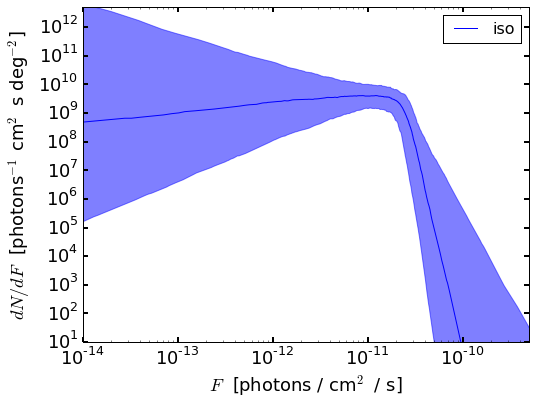

In [20]:
plt.figure(figsize=(8,6))
#plot medians
pdnds.plot_source_count_median('iso',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='blue',label='iso')

#plot band
pdnds.plot_source_count_band('iso',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='blue',label='iso',alpha=0.5)

plt.legend(fontsize=16) 

plt.yscale('log')
plt.xscale('log')
plt.xlim([1e-14,5e-10])
plt.ylim([1e1,5e12])

plt.tick_params(axis='x', length=5,width=2,labelsize=18)
plt.tick_params(axis='y',length=5,width=2,labelsize=18)
plt.xlabel('$F$  [photons / cm$^2$ / s]', fontsize=18)
plt.ylabel('$dN/dF$  [photons$^{-1}$ cm$^2$ s deg$^{-2}$]', fontsize=18)

plt.show()